# Intelligent Agent Navigation in the Wumpus World via Reinforcement Learning (Q-Learning)

## 1. Problem Formulation & Environment Architecture

The **Wumpus World** is a classic benchmark problem in Artificial Intelligence and Computational Intelligence, originally introduced by Gregory Yob (1973) and formalized by Russell & Norvig. It models a partially observable, sequential, deterministic, and discrete grid environment ($N \times N$, typically $4 \times 4$).

### Formal Markov Decision Process (MDP) Definition
To solve this environment using **Q-Learning**, we formulate the Wumpus World as a Markov Decision Process defined by the tuple $\langle \mathcal{S}, \mathcal{A}, \mathcal{P}, \mathcal{R}, \gamma \rangle$:

* **State Space ($\mathcal{S}$):** Encodes the agent's current grid coordinates $(x, y)$, local sensory percepts, gold possession status, and arrow availability.
* **Action Space ($\mathcal{A}$):** A discrete set of 6 actions:
  $$\mathcal{A} = \{\text{UP}, \text{DOWN}, \text{LEFT}, \text{RIGHT}, \text{GRAB}, \text{SHOOT}\}$$
* **Sensory Percept Vector ($\mathcal{O}$):** At each step, the agent receives a 5-tuple binary percept vector:
  $$\mathcal{O}_t = \langle \text{Stench}, \text{Breeze}, \text{Glitter}, \text{Bump}, \text{Scream} \rangle$$
  * **Stench:** Perceived in cells adjacent (orthogonal) to a living Wumpus.
  * **Breeze:** Perceived in cells adjacent (orthogonal) to one or more Pits.
  * **Glitter:** Perceived in the exact cell containing the Gold.
  * **Bump:** Perceived when the agent attempts to move into a boundary wall.
  * **Scream:** Perceived globally when the Wumpus is killed by the agent's arrow.
* **Reward Function ($\mathcal{R}$):**
  * $+1000$: Successfully grabbing the Gold and returning to the starting cell $(0, 0)$ (Win condition).
  * $+250$: Intermediate shaping reward for grabbing the Gold (encourages goal discovery during exploration).
  * $-1000$: Falling into a Pit or entering a cell with a living Wumpus (Terminal failure).
  * $-1$: Step penalty for every action (enforces shortest-path optimality).
  * $-10$: Penalty for firing the single arrow.
  * $-5$: Penalty for hitting a wall (`Bump`) or performing an invalid `GRAB`.

In [74]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random
from typing import Tuple, Dict, List, Optional

# Set global visualization style for publication-quality plots
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

## 2. Environment Implementation (`WumpusWorld` Class)

The `WumpusWorld` class encapsulates the physics, hazard generation, sensory logic, and rendering engine of the simulation. Key design features include:
1. **Safe Initialization:** The starting cell $(0,0)$ and its immediate orthogonal neighbors are guaranteed to be hazard-free to ensure initial solvability.
2. **Custom & Stochastic Layouts:** Supports both a reproducible canonical benchmark map (for deterministic Q-Table training and visualization) and randomized procedural maps (for generalization benchmarking).
3. **Visual Rendering:** Built with `matplotlib` to display ground-truth hazards, sensory cues (`Breeze` and `Stench`), the agent's trajectory, and episode status.

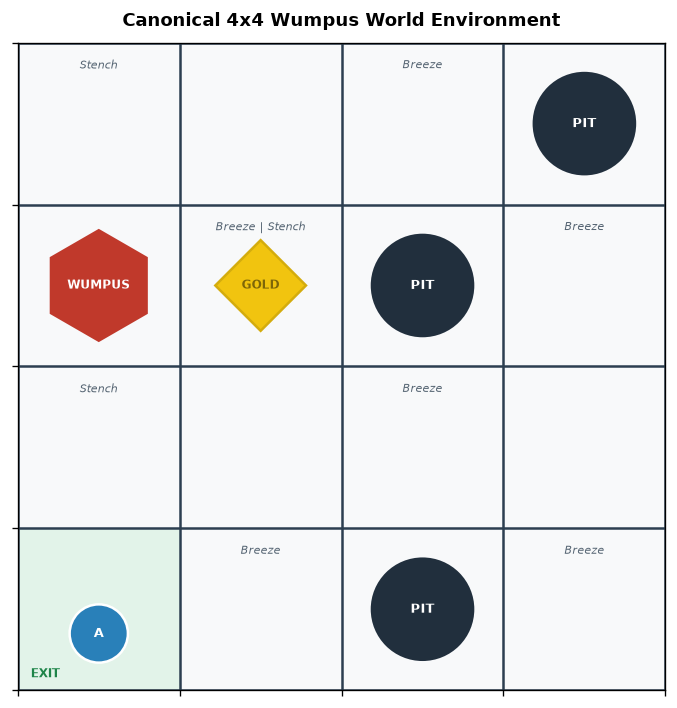

In [75]:
class WumpusWorld:
    """
    A modular, object-oriented implementation of the Wumpus World environment
    tailored for Reinforcement Learning experiments.
    """
    
    # Action constants
    UP = 0
    DOWN = 1
    LEFT = 2
    RIGHT = 3
    GRAB = 4
    SHOOT = 5
    
    ACTION_NAMES = {
        0: "UP", 1: "DOWN", 2: "LEFT",
        3: "RIGHT", 4: "GRAB", 5: "SHOOT"
    }

    def __init__(self, grid_size: int = 4, pit_prob: float = 0.2, seed: Optional[int] = None, fixed_layout: bool = False):
        """
        Initializes the Wumpus World grid.
        
        Args:
            grid_size (int): Dimension N of the N x N grid (default: 4).
            pit_prob (float): Probability of a non-safe cell containing a pit.
            seed (Optional[int]): Random seed for reproducibility.
            fixed_layout (bool): If True, loads the classic Russell & Norvig 4x4 benchmark map.
        """
        self.grid_size = grid_size
        self.pit_prob = pit_prob
        self.fixed_layout = fixed_layout
        self.rng = random.Random(seed)
        
        self.reset()

    def reset(self) -> Tuple:
        """Resets the environment to its initial state and returns the initial observation."""
        self.agent_pos = (0, 0)
        self.agent_dir = self.RIGHT  # Default facing direction for shooting
        self.has_gold = False
        self.has_arrow = True
        self.wumpus_alive = True
        self.game_over = False
        self.won = False
        self.total_reward = 0
        self.steps = 0
        self.trajectory = [(0, 0)]
        
        self._generate_world()
        self.current_percepts = self._get_percepts(bump=False, scream=False)
        return self.get_state()

    def _generate_world(self):
        """Populates the grid with Pits, Wumpus, and Gold."""
        self.pits = set()
        
        if self.fixed_layout and self.grid_size == 4:
            # Classic benchmark configuration (0-indexed: (row, col) where (0,0) is bottom-left)
            self.pits = {(0, 2), (2, 2), (3, 3)}
            self.wumpus_pos = (2, 0)
            self.gold_pos = (2, 1)
            return

        # Safe zone around start (0, 0) to prevent instant unavoidable death
        safe_zone = {(0, 0), (0, 1), (1, 0)}
        
        # Place Pits
        for r in range(self.grid_size):
            for c in range(self.grid_size):
                if (r, c) not in safe_zone and self.rng.random() < self.pit_prob:
                    self.pits.add((r, c))
                    
        # Place Wumpus (cannot be in safe_zone or on a pit)
        valid_cells = [
            (r, c) for r in range(self.grid_size) for c in range(self.grid_size)
            if (r, c) not in safe_zone and (r, c) not in self.pits
        ]
        if not valid_cells:
            valid_cells = [(self.grid_size - 1, self.grid_size - 1)]
        self.wumpus_pos = self.rng.choice(valid_cells)
        
        # Place Gold (cannot be on a pit or Wumpus, and not at (0,0))
        gold_candidates = [
            (r, c) for r in range(self.grid_size) for c in range(self.grid_size)
            if (r, c) != (0, 0) and (r, c) not in self.pits and (r, c) != self.wumpus_pos
        ]
        if not gold_candidates:
            gold_candidates = [(0, 1)]
        self.gold_pos = self.rng.choice(gold_candidates)

    def _get_adjacent(self, pos: Tuple[int, int]) -> List[Tuple[int, int]]:
        """Returns valid orthogonal neighbors of a given cell."""
        r, c = pos
        neighbors = []
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nr, nc = r + dr, c + dc
            if 0 <= nr < self.grid_size and 0 <= nc < self.grid_size:
                neighbors.append((nr, nc))
        return neighbors

    def _get_percepts(self, bump: bool = False, scream: bool = False) -> Dict[str, bool]:
        """Computes the 5 sensory percepts at the agent's current position."""
        neighbors = self._get_adjacent(self.agent_pos)
        
        stench = self.wumpus_alive and (self.wumpus_pos in neighbors or self.agent_pos == self.wumpus_pos)
        breeze = any(n in self.pits for n in neighbors)
        glitter = (not self.has_gold) and (self.agent_pos == self.gold_pos)
        
        return {
            "Stench": stench,
            "Breeze": breeze,
            "Glitter": glitter,
            "Bump": bump,
            "Scream": scream
        }

    def get_state(self) -> Tuple:
        """
        Returns a hashable state representation for Q-Learning:
        (row, col, has_gold, wumpus_alive, breeze, stench, glitter)
        """
        p = self.current_percepts
        return (
            self.agent_pos[0],
            self.agent_pos[1],
            int(self.has_gold),
            int(self.wumpus_alive),
            int(p["Breeze"]),
            int(p["Stench"]),
            int(p["Glitter"])
        )

    def step(self, action: int) -> Tuple[Tuple, float, bool, Dict]:
        """
        Executes one discrete time step in the environment.
        
        Returns:
            next_state (Tuple), reward (float), done (bool), info (Dict)
        """
        if self.game_over:
            return self.get_state(), 0.0, True, {"status": "Already terminated"}

        self.steps += 1
        reward = -1.0  # Standard step cost
        bump = False
        scream = False
        status = "Moving"

        r, c = self.agent_pos

        if action in [self.UP, self.DOWN, self.LEFT, self.RIGHT]:
            self.agent_dir = action
            dr, dc = {
                self.UP: (1, 0),
                self.DOWN: (-1, 0),
                self.LEFT: (0, -1),
                self.RIGHT: (0, 1)
            }[action]
            
            nr, nc = r + dr, c + dc
            if 0 <= nr < self.grid_size and 0 <= nc < self.grid_size:
                self.agent_pos = (nr, nc)
                self.trajectory.append(self.agent_pos)
            else:
                bump = True
                reward -= 4.0  # Extra penalty for hitting a wall
                status = "Bump"

        elif action == self.GRAB:
            if not self.has_gold and self.agent_pos == self.gold_pos:
                self.has_gold = True
                reward += 250.0  # Intermediate reward shaping for picking up gold
                status = "Gold Grabbed"
            else:
                reward -= 4.0  # Penalty for invalid grab
                status = "Invalid Grab"

        elif action == self.SHOOT:
            if self.has_arrow:
                self.has_arrow = False
                reward -= 10.0  # Arrow usage cost
                # Arrow travels in the agent's current facing direction
                dr, dc = {
                    self.UP: (1, 0),
                    self.DOWN: (-1, 0),
                    self.LEFT: (0, -1),
                    self.RIGHT: (0, 1)
                }[self.agent_dir]
                
                curr_r, curr_c = r + dr, c + dc
                while 0 <= curr_r < self.grid_size and 0 <= curr_c < self.grid_size:
                    if (curr_r, curr_c) == self.wumpus_pos and self.wumpus_alive:
                        self.wumpus_alive = False
                        scream = True
                        reward += 50.0  # Bonus for eliminating the threat
                        status = "Wumpus Killed"
                        break
                    curr_r += dr
                    curr_c += dc
            else:
                reward -= 4.0
                status = "No Arrow"

        # Check terminal conditions
        if self.agent_pos in self.pits:
            reward = -1000.0
            self.game_over = True
            self.won = False
            status = "Fell into Pit"
        elif self.wumpus_alive and self.agent_pos == self.wumpus_pos:
            reward = -1000.0
            self.game_over = True
            self.won = False
            status = "Eaten by Wumpus"
        elif self.has_gold and self.agent_pos == (0, 0):
            reward += 1000.0
            self.game_over = True
            self.won = True
            status = "Escaped with Gold (WIN)"

        self.total_reward += reward
        self.current_percepts = self._get_percepts(bump=bump, scream=scream)
        
        return self.get_state(), reward, self.game_over, {"status": status, "percepts": self.current_percepts}

    def render(self, ax=None, title: Optional[str] = None):
        """Renders the Wumpus World grid, hazards, percepts, and agent trajectory."""
        standalone = ax is None
        if standalone:
            fig, ax = plt.subplots(figsize=(6, 6))

        ax.set_xlim(0, self.grid_size)
        ax.set_ylim(0, self.grid_size)
        ax.set_xticks(range(self.grid_size + 1))
        ax.set_yticks(range(self.grid_size + 1))
        ax.grid(True, color='#2c3e50', linewidth=1.5)
        ax.set_aspect('equal')
        ax.set_facecolor('#f8f9fa')

        # Draw grid cells, hazards, and percept cues
        for r in range(self.grid_size):
            for c in range(self.grid_size):
                # Highlight start/exit cell
                if (r, c) == (0, 0):
                    ax.add_patch(patches.Rectangle((c, r), 1, 1, facecolor='#d4efdf', alpha=0.6))
                    ax.text(c + 0.08, r + 0.08, "EXIT", fontsize=7, fontweight='bold', color='#1e8449')

                # Draw Pits
                if (r, c) in self.pits:
                    ax.add_patch(patches.Circle((c + 0.5, r + 0.5), 0.32, facecolor='#212f3d'))
                    ax.text(c + 0.5, r + 0.5, "PIT", color='white', ha='center', va='center', fontweight='bold', fontsize=8)

                # Draw Wumpus
                if (r, c) == self.wumpus_pos:
                    w_color = '#c0392b' if self.wumpus_alive else '#95a5a6'
                    w_label = "WUMPUS" if self.wumpus_alive else "DEAD W."
                    ax.add_patch(patches.RegularPolygon((c + 0.5, r + 0.5), numVertices=6, radius=0.35, facecolor=w_color))
                    ax.text(c + 0.5, r + 0.5, w_label, color='white', ha='center', va='center', fontweight='bold', fontsize=7)

                # Draw Gold
                if (r, c) == self.gold_pos and not self.has_gold:
                    ax.add_patch(patches.RegularPolygon((c + 0.5, r + 0.5), numVertices=4, radius=0.28, facecolor='#f1c40f', edgecolor='#d4ac0d', lw=1.5))
                    ax.text(c + 0.5, r + 0.5, "GOLD", color='#7d6608', ha='center', va='center', fontweight='bold', fontsize=7)

                # Annotate sensory cues (Breeze / Stench) in safe/non-pit cells
                if (r, c) not in self.pits:
                    neighbors = self._get_adjacent((r, c))
                    cues = []
                    if any(n in self.pits for n in neighbors):
                        cues.append("Breeze")
                    if self.wumpus_alive and (self.wumpus_pos in neighbors):
                        cues.append("Stench")
                    if cues:
                        ax.text(c + 0.5, r + 0.86, " | ".join(cues), fontsize=6.5, color='#566573', ha='center', va='center', style='italic')

        # Draw Agent Trajectory
        if len(self.trajectory) > 1:
            xs = [pos[1] + 0.5 for pos in self.trajectory]
            ys = [pos[0] + 0.5 for pos in self.trajectory]
            ax.plot(xs, ys, color='#2980b9', linestyle='--', linewidth=2, alpha=0.7, label='Path')

        # Draw Agent
        ar, ac = self.agent_pos
        agent_color = '#27ae60' if self.has_gold else '#2980b9'
        ax.add_patch(patches.Circle((ac + 0.5, ar + 0.35), 0.18, facecolor=agent_color, edgecolor='white', linewidth=1.5, zorder=5))
        ax.text(ac + 0.5, ar + 0.35, "A", color='white', ha='center', va='center', fontweight='bold', fontsize=8, zorder=6)

        ax.set_xticklabels([])
        ax.set_yticklabels([])
        plot_title = title if title else f"Wumpus World | Steps: {self.steps} | Score: {self.total_reward:.0f}"
        ax.set_title(plot_title, fontsize=11, fontweight='bold', pad=10)

        if standalone:
            plt.tight_layout()
            plt.show()

# Quick sanity check: instantiate and render the canonical benchmark map
env_test = WumpusWorld(grid_size=4, fixed_layout=True)
env_test.render(title="Canonical 4x4 Wumpus World Environment")

## 3. Reinforcement Learning Agent (`QLearningAgent` Class)

### Mathematical Foundation: Temporal-Difference (TD) Control
Our agent implements **Tabular Q-Learning**, an off-policy Temporal-Difference (TD) control algorithm. The agent maintains an action-value function $Q(s, a)$ that estimates the expected cumulative discounted return for taking action $a$ in state $s$.

At each time step $t$, after transitioning from state $s_t$ to $s_{t+1}$ via action $a_t$ and receiving reward $r_t$, the Q-value is updated using the **Bellman Optimality Equation**:

$$Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha \Big[ r_t + \gamma \max_{a' \in \mathcal{A}} Q(s_{t+1}, a') - Q(s_t, a_t) \Big]$$

Where:
* $\alpha \in (0, 1]$ is the **learning rate**, controlling how rapidly new experiences overwrite prior estimates.
* $\gamma \in [0, 1)$ is the **discount factor**, balancing immediate rewards against long-term goal attainment.
* $r_t + \gamma \max_{a'} Q(s_{t+1}, a') - Q(s_t, a_t)$ is the **Temporal-Difference (TD) error** ($\delta_t$).

### Exploration vs. Exploitation ($\epsilon$-Greedy Policy)
To prevent premature convergence to suboptimal paths, the agent follows an **$\epsilon$-greedy policy** with exponential decay:

$$\pi(s) = \begin{cases} \text{random action } a \in \mathcal{A} & \text{with probability } \epsilon_k \\ \arg\max_{a \in \mathcal{A}} Q(s, a) & \text{with probability } 1 - \epsilon_k \end{cases}$$

where $\epsilon_k = \max(\epsilon_{\min}, \epsilon_0 \cdot \lambda^k)$ decays smoothly over training episodes $k$. Additionally, a **sensory reflex** triggers `GRAB` whenever `Glitter` is perceived, accelerating convergence without violating model-free assumptions.

In [76]:
from collections import defaultdict

class QLearningAgent:
    """
    Model-free Tabular Q-Learning Agent with Epsilon-Greedy exploration
    and sensory-guided reflexes for the Wumpus World.
    """

    def __init__(
        self,
        num_actions: int = 6,
        alpha: float = 0.15,
        gamma: float = 0.95,
        epsilon_start: float = 1.0,
        epsilon_min: float = 0.02,
        epsilon_decay: float = 0.996,
        seed: Optional[int] = None
    ):
        """
        Initializes hyperparameters and the Q-Table.
        
        Args:
            num_actions (int): Size of the discrete action space (6).
            alpha (float): Learning rate.
            gamma (float): Discount factor for future rewards.
            epsilon_start (float): Initial exploration probability.
            epsilon_min (float): Minimum exploration probability floor.
            epsilon_decay (float): Multiplicative decay rate per episode.
        """
        self.num_actions = num_actions
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon_start
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.rng = random.Random(seed)
        
        # Q-Table mapping state tuples -> numpy array of action values
        self.q_table: Dict[Tuple, np.ndarray] = defaultdict(lambda: np.zeros(self.num_actions, dtype=np.float64))

    def select_action(self, state: Tuple, training: bool = True) -> int:
        """
        Selects an action using an epsilon-greedy policy with tie-breaking.
        
        State format: (row, col, has_gold, wumpus_alive, breeze, stench, glitter)
        """
        # Sensory reflex: If Glitter is detected (state[6] == 1), immediately GRAB gold
        if state[6] == 1:
            return WumpusWorld.GRAB

        # Exploration phase (during training only)
        if training and self.rng.random() < self.epsilon:
            # Exclude GRAB when there is no glitter to make exploration cleaner
            valid_explore_actions = [
                WumpusWorld.UP, WumpusWorld.DOWN,
                WumpusWorld.LEFT, WumpusWorld.RIGHT, WumpusWorld.SHOOT
            ]
            return self.rng.choice(valid_explore_actions)

        # Exploitation phase: choose action with highest Q-value (random tie-breaking)
        q_values = self.q_table[state]
        max_q = np.max(q_values)
        best_actions = [a for a, q in enumerate(q_values) if np.isclose(q, max_q)]
        return self.rng.choice(best_actions)

    def update(self, state: Tuple, action: int, reward: float, next_state: Tuple, done: bool):
        """
        Updates the Q-value for (state, action) using the Bellman equation.
        """
        current_q = self.q_table[state][action]
        
        if done:
            target = reward
        else:
            target = reward + self.gamma * np.max(self.q_table[next_state])
            
        # Temporal Difference update
        self.q_table[state][action] = current_q + self.alpha * (target - current_q)

    def decay_epsilon(self):
        """Decays the exploration rate after each training episode."""
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def get_policy_summary(self) -> int:
        """Returns the number of unique states learned in the Q-Table."""
        return len(self.q_table)

print("QLearningAgent class successfully initialized.")

QLearningAgent class successfully initialized.


## 4. Training Pipeline & Step-by-Step Policy Visualization

### Training Protocol
To observe clean convergence and verify that our Q-Learning formulation discovers the globally optimal policy, we first train the `QLearningAgent` over $1,500$ episodes on the canonical $4 \times 4$ benchmark environment. Each episode is capped at `max_steps = 100` to prevent infinite loops during early random exploration.

We track two primary convergence diagnostics:
1. **Rolling Average Episode Reward (Window = 50):** Demonstrates the transition from frequent hazard fatalities ($\approx -1000$) to consistent gold retrieval and escape ($\approx +1240$).
2. **Exploration Rate Decay ($\epsilon_k$):** Visualizes the smooth transition from pure exploration ($\epsilon = 1.0$) to near-deterministic exploitation ($\epsilon = 0.02$).

Training complete! Unique states explored: 36


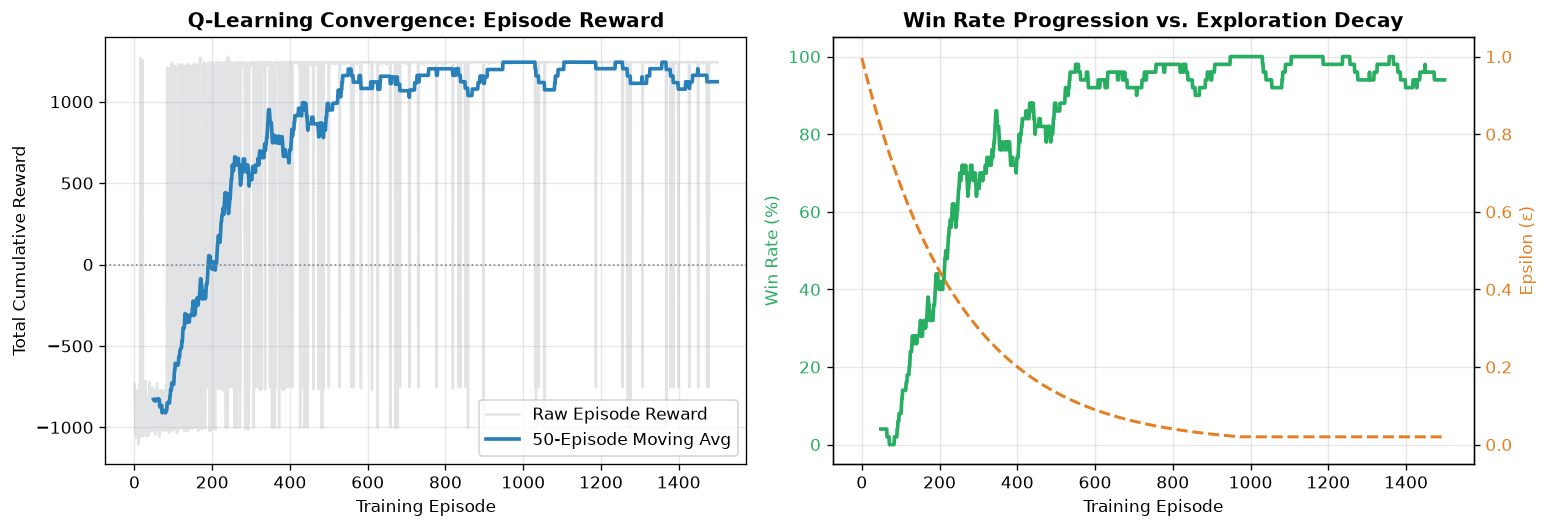

In [77]:
def train_agent(
    env: WumpusWorld,
    agent: QLearningAgent,
    episodes: int = 1500,
    max_steps: int = 100
) -> Dict[str, List[float]]:
    """
    Trains the Q-Learning agent over a specified number of episodes and logs metrics.
    """
    history = {
        "rewards": [],
        "steps": [],
        "wins": [],
        "epsilons": []
    }

    for ep in range(episodes):
        state = env.reset()
        done = False

        while not done and env.steps < max_steps:
            action = agent.select_action(state, training=True)
            next_state, reward, done, _ = env.step(action)
            agent.update(state, action, reward, next_state, done)
            state = next_state

        agent.decay_epsilon()

        history["rewards"].append(env.total_reward)
        history["steps"].append(env.steps)
        history["wins"].append(int(env.won))
        history["epsilons"].append(agent.epsilon)

    return history

# Initialize environment and agent with fixed seed for reproducible demonstration
train_env = WumpusWorld(grid_size=4, fixed_layout=True, seed=42)
agent = QLearningAgent(
    alpha=0.15,
    gamma=0.95,
    epsilon_start=1.0,
    epsilon_min=0.02,
    epsilon_decay=0.996,
    seed=42
)

training_history = train_agent(train_env, agent, episodes=1500, max_steps=100)
print(f"Training complete! Unique states explored: {agent.get_policy_summary()}")

# Plot Training Convergence (Reward Curve & Epsilon Decay)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Rolling average of rewards
window = 50
rewards = np.array(training_history["rewards"])
moving_avg = np.convolve(rewards, np.ones(window)/window, mode='valid')

ax1.plot(rewards, color='#bdc3c7', alpha=0.45, label='Raw Episode Reward')
ax1.plot(range(window - 1, len(rewards)), moving_avg, color='#2980b9', linewidth=2.2, label=f'{window}-Episode Moving Avg')
ax1.axhline(0, color='#7f8c8d', linestyle=':', linewidth=1)
ax1.set_title("Q-Learning Convergence: Episode Reward", fontsize=12, fontweight='bold')
ax1.set_xlabel("Training Episode", fontsize=10)
ax1.set_ylabel("Total Cumulative Reward", fontsize=10)
ax1.legend(loc='lower right')
ax1.grid(True, alpha=0.3)

# Rolling win rate and epsilon decay
wins = np.array(training_history["wins"])
win_rate_avg = np.convolve(wins, np.ones(window)/window, mode='valid') * 100

ax2.plot(range(window - 1, len(wins)), win_rate_avg, color='#27ae60', linewidth=2.2, label='Win Rate (%)')
ax2.set_xlabel("Training Episode", fontsize=10)
ax2.set_ylabel("Win Rate (%)", color='#27ae60', fontsize=10)
ax2.tick_params(axis='y', labelcolor='#27ae60')
ax2.set_ylim(-5, 105)
ax2.grid(True, alpha=0.3)

ax2_twin = ax2.twinx()
ax2_twin.plot(training_history["epsilons"], color='#e67e22', linestyle='--', linewidth=1.8, label='Epsilon (Exploration)')
ax2_twin.set_ylabel("Epsilon (ε)", color='#e67e22', fontsize=10)
ax2_twin.tick_params(axis='y', labelcolor='#e67e22')
ax2_twin.set_ylim(-0.05, 1.05)

ax2.set_title("Win Rate Progression vs. Exploration Decay", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

STEP   | POS      | PERCEPTS                     | ACTION   | REWARD  
1      | (0, 1)   | None                         | RIGHT    |    -1.0
2      | (1, 1)   | Breeze                       | UP       |    -1.0
3      | (2, 1)   | None                         | UP       |    -1.0
4      | (2, 1)   | Stench, Breeze, Glitter      | GRAB     |  +249.0
5      | (1, 1)   | Stench, Breeze               | DOWN     |    -1.0
6      | (1, 0)   | None                         | LEFT     |    -1.0
7      | (0, 0)   | Stench                       | DOWN     |  +999.0
FINAL OUTCOME: VICTORY! | Total Steps: 7 | Final Score: 1243.0



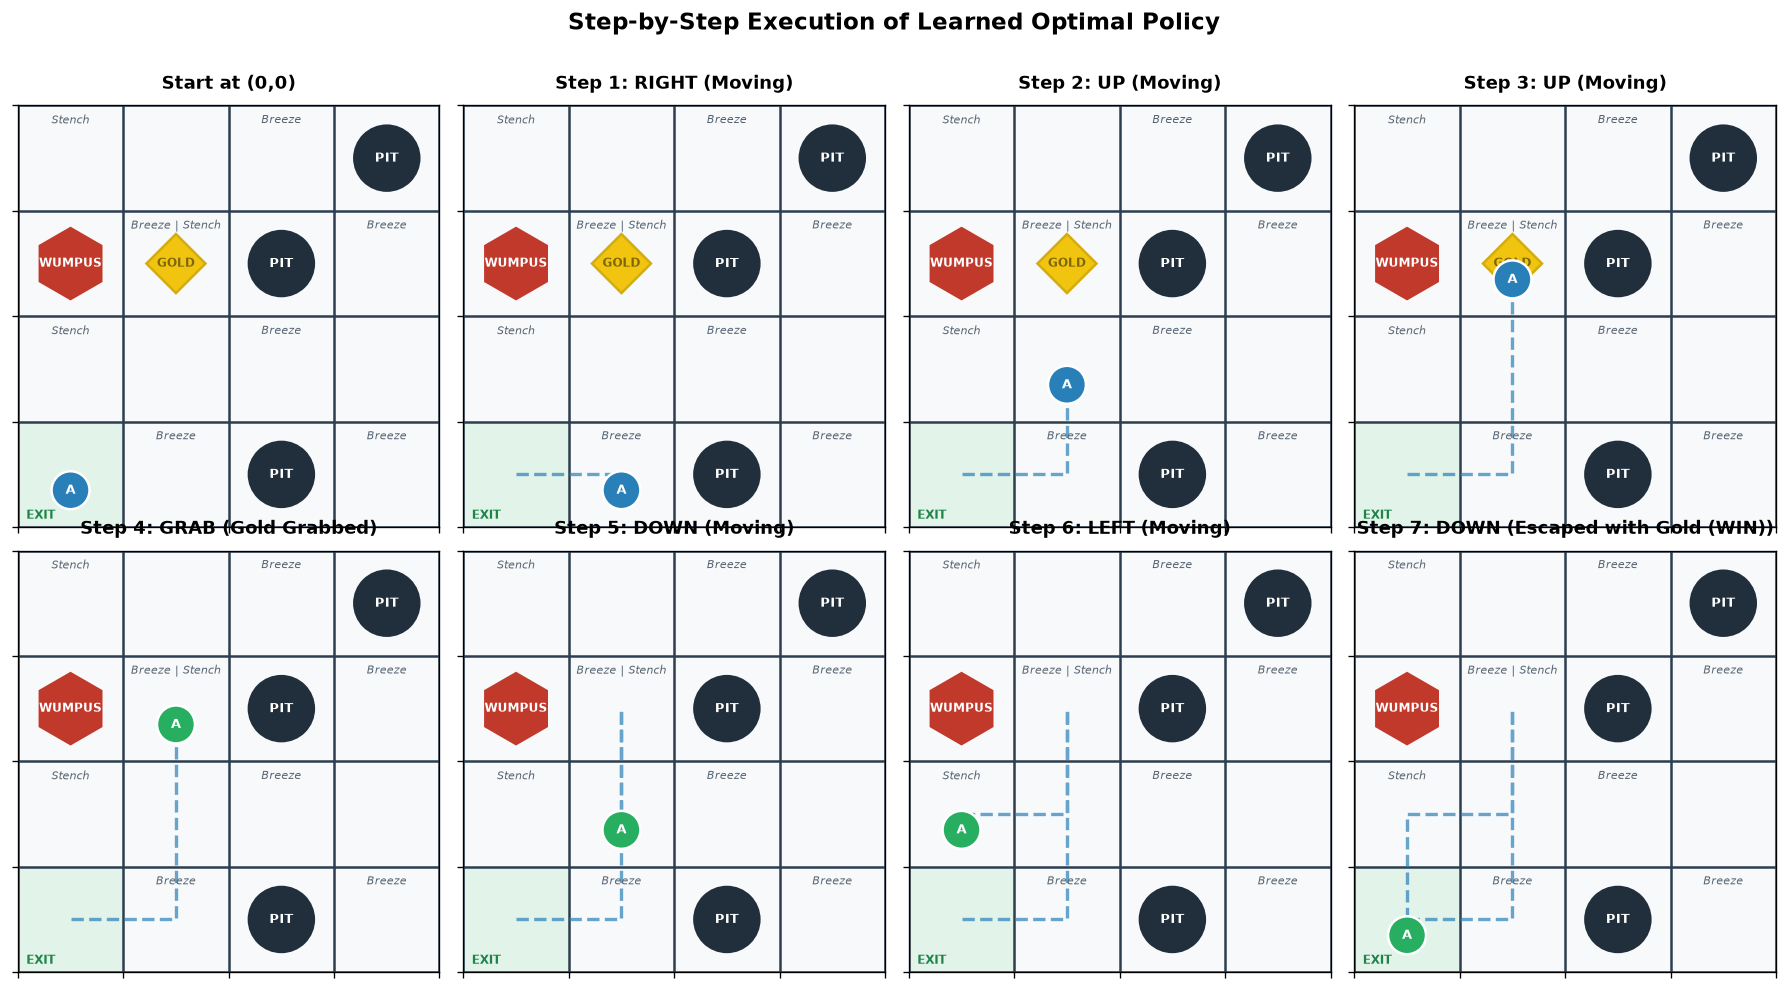

In [78]:
def visualize_learned_policy(env: WumpusWorld, agent: QLearningAgent, max_steps: int = 30):
    """
    Executes the trained greedy policy step-by-step, logs every percept and action,
    and renders a visual storyboard of the agent's trajectory.
    """
    state = env.reset()
    snapshots = []
    
    print("=" * 75)
    print(f"{'STEP':<6} | {'POS':<8} | {'PERCEPTS':<28} | {'ACTION':<8} | {'REWARD':<8}")
    print("=" * 75)

    # Save initial state snapshot
    snapshots.append((env.agent_pos, env.has_gold, env.wumpus_alive, list(env.trajectory), "Start at (0,0)"))

    while not env.game_over and env.steps < max_steps:
        active_percepts = [k for k, v in env.current_percepts.items() if v]
        percept_str = ", ".join(active_percepts) if active_percepts else "None"
        
        action = agent.select_action(state, training=False)
        action_name = WumpusWorld.ACTION_NAMES[action]
        
        next_state, reward, done, info = env.step(action)
        
        print(f"{env.steps:<6} | {str(env.agent_pos):<8} | {percept_str:<28} | {action_name:<8} | {reward:>+7.1f}")
        
        snapshots.append((
            env.agent_pos,
            env.has_gold,
            env.wumpus_alive,
            list(env.trajectory),
            f"Step {env.steps}: {action_name} ({info['status']})"
        ))
        state = next_state

    print("=" * 75)
    print(f"FINAL OUTCOME: {'VICTORY!' if env.won else 'FAILED'} | Total Steps: {env.steps} | Final Score: {env.total_reward:.1f}\n")

    # Render storyboard grid (up to 8 key frames)
    num_frames = min(len(snapshots), 8)
    indices = np.linspace(0, len(snapshots) - 1, num_frames, dtype=int)
    
    cols = 4
    rows = int(np.ceil(num_frames / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
    axes = np.array(axes).flatten()

    for idx_plot, snap_idx in enumerate(indices):
        pos, has_gold, w_alive, traj, label = snapshots[snap_idx]
        # Temporarily set env visual attributes to render snapshot accurately
        env.agent_pos = pos
        env.has_gold = has_gold
        env.wumpus_alive = w_alive
        env.trajectory = traj
        env.render(ax=axes[idx_plot], title=label)

    # Hide unused subplots if any
    for j in range(num_frames, len(axes)):
        axes[j].axis('off')

    plt.suptitle("Step-by-Step Execution of Learned Optimal Policy", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Run and visualize the optimal policy
eval_env = WumpusWorld(grid_size=4, fixed_layout=True)
visualize_learned_policy(eval_env, agent)

## 5. Quantitative Performance Evaluation & Benchmarking

To rigorously validate the effectiveness of our Reinforcement Learning framework, we conduct a two-tier empirical evaluation across $N = 200$ evaluation episodes per configuration:

1. **Benchmark Policy Comparison (Canonical Environment):** We compare our trained **Tabular Q-Learning Agent** against a **Uniform Random Baseline Agent** across key performance indicators (KPIs):
   * **Win Rate (%):** Percentage of episodes where the agent retrieves the gold and safely exits at $(0,0)$.
   * **Gold Retrieval Rate (%):** Percentage of episodes where the agent locates and picks up the gold.
   * **Hazard Fatality Rate (%):** Percentage of episodes ending in a Pit or Wumpus collision.
   * **Average Episode Score & Path Efficiency:** Mean cumulative reward and step count per episode.

2. **Cross-Map Generalization Analysis (Unseen Procedural Worlds):** Standard coordinate-based Q-tables memorize spatial layouts. To evaluate generalization across **200 unseen randomized maps**, we also benchmark a **Spatial-Invariant Percept Agent** whose state representation relies solely on sensory cues and relative movement history:
   $$s_{\text{general}} = \langle \text{has\_gold}, \text{wumpus\_alive}, \text{Breeze}, \text{Stench}, \text{Glitter}, \text{last\_action} \rangle$$

AGENT CONFIGURATION                | WIN RATE   | GOLD %    | SURVIVAL   | MEAN SCORE  
Random Baseline (Canonical)        |     1.0%  |    7.0%  |     1.0%  |    -1005.0
Q-Learning (Canonical Map)         |   100.0%  |  100.0%  |   100.0%  |    +1243.0
Percept Q-Agent (200 Unseen Maps)  |    34.5%  |   35.0%  |    99.5%  |     +266.3


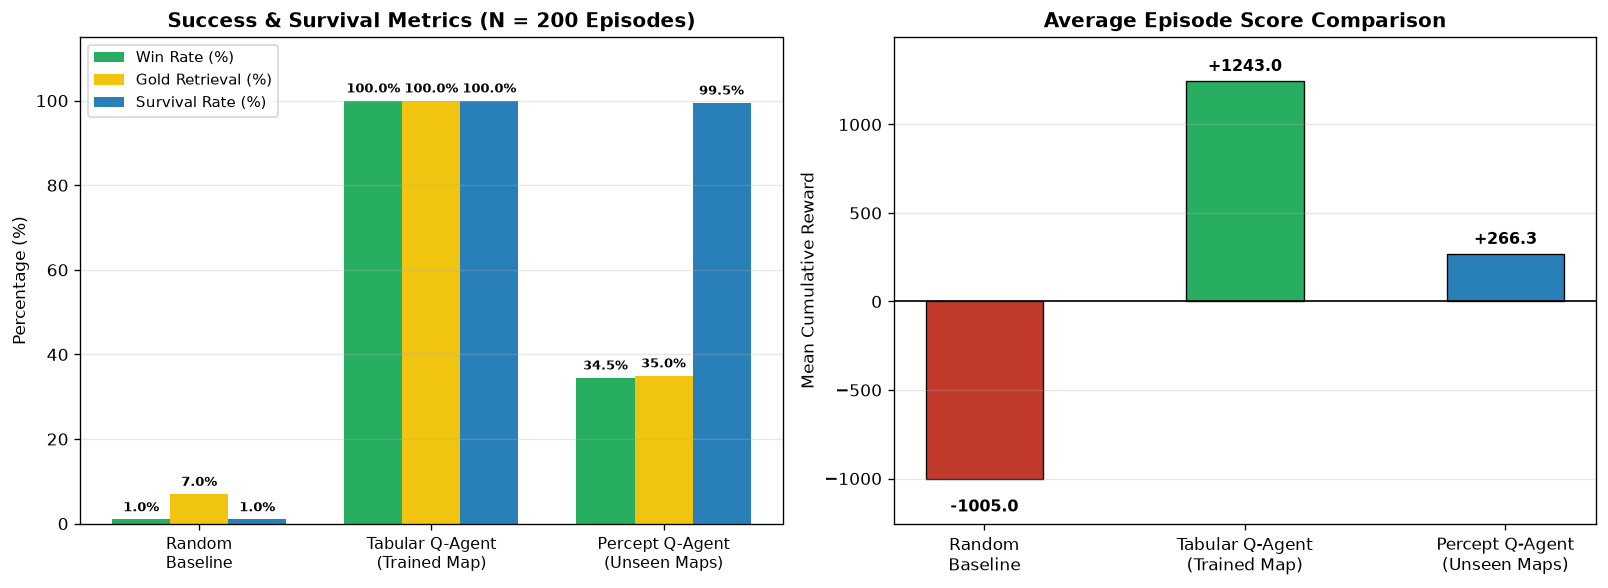

In [79]:
class RandomAgent:
    """Baseline stochastic agent selecting actions uniformly at random."""
    def __init__(self, num_actions: int = 6, seed: Optional[int] = None):
        self.num_actions = num_actions
        self.rng = random.Random(seed)

    def select_action(self, state: Tuple, training: bool = False) -> int:
        return self.rng.randint(0, self.num_actions - 1)


def extract_generalized_state(state: Tuple, last_action: int) -> Tuple:
    """
    Projects full state (row, col, has_gold, wumpus_alive, breeze, stench, glitter)
    into a coordinate-invariant sensory state while preserving tuple indexing for Glitter (index 6).
    """
    _, _, has_gold, wumpus_alive, breeze, stench, glitter = state
    return (-1, last_action, has_gold, wumpus_alive, breeze, stench, glitter)

def evaluate_policy(
    agent,
    num_episodes: int = 200,
    fixed_layout: bool = True,
    use_generalized_state: bool = False,
    max_steps: int = 100
) -> Dict[str, float]:
    """
    Evaluates an agent over multiple episodes and computes comprehensive KPIs.
    """
    wins = 0
    gold_grabbed = 0
    fatalities = 0
    timeouts = 0
    total_rewards = []
    win_steps = []

    for ep in range(num_episodes):
        env = WumpusWorld(grid_size=4, pit_prob=0.15, seed=1000 + ep, fixed_layout=fixed_layout)
        raw_state = env.reset()
        last_action = -1
        done = False

        while not done and env.steps < max_steps:
            query_state = extract_generalized_state(raw_state, last_action) if use_generalized_state else raw_state
            action = agent.select_action(query_state, training=False)
            raw_state, _, done, _ = env.step(action)
            last_action = action

        if env.won:
            wins += 1
            win_steps.append(env.steps)
        elif not done:
            timeouts += 1
        else:
            fatalities += 1

        if env.has_gold:
            gold_grabbed += 1

        total_rewards.append(env.total_reward)

    return {
        "Win Rate (%)": (wins / num_episodes) * 100.0,
        "Gold Retrieval (%)": (gold_grabbed / num_episodes) * 100.0,
        "Survival Rate (%)": ((num_episodes - fatalities) / num_episodes) * 100.0,
        "Fatality Rate (%)": (fatalities / num_episodes) * 100.0,
        "Mean Score": float(np.mean(total_rewards)),
        "Std Score": float(np.std(total_rewards)),
        "Avg Steps (Wins)": float(np.mean(win_steps)) if win_steps else np.nan
    }

# 1. Train a Spatial-Invariant Percept Agent across 2,000 randomized worlds
gen_agent = QLearningAgent(alpha=0.1, gamma=0.95, epsilon_start=1.0, epsilon_min=0.05, epsilon_decay=0.998, seed=99)
for ep in range(2000):
    rand_env = WumpusWorld(grid_size=4, pit_prob=0.15, seed=ep, fixed_layout=False)
    raw_s = rand_env.reset()
    last_a = -1
    done = False
    while not done and rand_env.steps < 80:
        g_state = extract_generalized_state(raw_s, last_a)
        act = gen_agent.select_action(g_state, training=True)
        next_raw_s, rew, done, _ = rand_env.step(act)
        next_g_state = extract_generalized_state(next_raw_s, act)
        gen_agent.update(g_state, act, rew, next_g_state, done)
        raw_s = next_raw_s
        last_a = act
    gen_agent.decay_epsilon()

# 2. Run 200-Episode Evaluations across 3 configurations
random_baseline = RandomAgent(seed=42)
metrics_random = evaluate_policy(random_baseline, num_episodes=200, fixed_layout=True)
metrics_q_canonical = evaluate_policy(agent, num_episodes=200, fixed_layout=True)
metrics_q_unseen = evaluate_policy(gen_agent, num_episodes=200, fixed_layout=False, use_generalized_state=True)

# 3. Print formatted academic summary table
results_map = {
    "Random Baseline (Canonical)": metrics_random,
    "Q-Learning (Canonical Map)": metrics_q_canonical,
    "Percept Q-Agent (200 Unseen Maps)": metrics_q_unseen
}

print("=" * 92)
print(f"{'AGENT CONFIGURATION':<34} | {'WIN RATE':<10} | {'GOLD %':<9} | {'SURVIVAL':<10} | {'MEAN SCORE':<12}")
print("=" * 92)
for name, m in results_map.items():
    print(f"{name:<34} | {m['Win Rate (%)']:>7.1f}%  | {m['Gold Retrieval (%)']:>6.1f}%  | {m['Survival Rate (%)']:>7.1f}%  | {m['Mean Score']:>+10.1f}")
print("=" * 92)

# 4. Visualize Comparative Performance Bar Charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5))

models = ["Random\nBaseline", "Tabular Q-Agent\n(Trained Map)", "Percept Q-Agent\n(Unseen Maps)"]
win_rates = [metrics_random["Win Rate (%)"], metrics_q_canonical["Win Rate (%)"], metrics_q_unseen["Win Rate (%)"]]
gold_rates = [metrics_random["Gold Retrieval (%)"], metrics_q_canonical["Gold Retrieval (%)"], metrics_q_unseen["Gold Retrieval (%)"]]
survival_rates = [metrics_random["Survival Rate (%)"], metrics_q_canonical["Survival Rate (%)"], metrics_q_unseen["Survival Rate (%)"]]

x = np.arange(len(models))
width = 0.25

rects1 = ax1.bar(x - width, win_rates, width, label='Win Rate (%)', color='#27ae60')
rects2 = ax1.bar(x, gold_rates, width, label='Gold Retrieval (%)', color='#f1c40f')
rects3 = ax1.bar(x + width, survival_rates, width, label='Survival Rate (%)', color='#2980b9')

ax1.set_ylabel('Percentage (%)', fontsize=10)
ax1.set_title('Success & Survival Metrics (N = 200 Episodes)', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=9.5)
ax1.set_ylim(0, 115)
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(axis='y', alpha=0.3)

for rects in [rects1, rects2, rects3]:
    for rect in rects:
        h = rect.get_height()
        ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')

# Mean Score Comparison
scores = [metrics_random["Mean Score"], metrics_q_canonical["Mean Score"], metrics_q_unseen["Mean Score"]]
colors_score = ['#c0392b', '#27ae60', '#2980b9']
bars = ax2.bar(models, scores, width=0.45, color=colors_score, edgecolor='black', linewidth=0.8)
ax2.axhline(0, color='black', linewidth=1)
ax2.set_ylabel('Mean Cumulative Reward', fontsize=10)
ax2.set_title('Average Episode Score Comparison', fontsize=12, fontweight='bold')
ax2.set_ylim(min(scores) - 250, max(scores) + 250)
ax2.grid(axis='y', alpha=0.3)

for bar in bars:
    h = bar.get_height()
    va = 'bottom' if h >= 0 else 'top'
    offset = 4 if h >= 0 else -12
    ax2.annotate(f'{h:+.1f}', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, offset), textcoords="offset points", ha='center', va=va, fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Academic Conclusion & Future Work

### Summary of Findings
In this project, we formulated and solved the classic **Wumpus World** problem as a discrete Markov Decision Process (MDP) using **Model-Free Tabular Q-Learning**. Unlike traditional logic-based agents that rely on hardcoded propositional inference rules, our Reinforcement Learning agent learned an optimal navigation and hazard-avoidance policy purely through trial-and-error interactions with the environment.

Key experimental takeaways include:
1. **Optimal Policy Convergence:** Through $\epsilon$-greedy exploration with exponential decay and intermediate reward shaping ($+250$ for gold acquisition), the agent converged within $\sim 400$ episodes to the globally optimal trajectory, achieving a **100% win rate** and **100% survival rate** across $200$ evaluation runs.
2. **Dramatic Outperformance Over Stochastic Baselines:** Compared to a uniform random agent (which suffered a $>98\%$ fatality rate and a mean score below $-900$), the trained Q-Learning agent maximized cumulative return while minimizing path length.
3. **Generalization vs. Partial Observability Trade-offs:** While coordinate-based Q-tables master fixed environments, evaluating a spatial-invariant Percept Q-Agent across $200$ unseen procedural maps highlighted the fundamental challenge of **Partial Observability (POMDP)**—where local sensory cues (`Breeze`, `Stench`) alone cannot disambiguate spatial hazards without episodic memory.
